# Aula 7.2 — Desafio: investigando fronteiras de decisão com SVM

Dataset `make_moons(n_samples=300, noise=0.20, random_state=42)`: duas "luas" entrelaçadas que nenhuma reta separa por completo.

Vamos comparar o **SVM linear** com o **SVM RBF**, ver como os hiperparâmetros **C** e **gamma** mudam a fronteira e terminar com a busca automática pelo `GridSearchCV`.

## 01 · Criar o dataset

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

X, y = make_moons(n_samples=300, noise=0.20, random_state=42)
print("X:", X.shape, "| y:", y.shape, "| amostras por classe:", np.bincount(y))

X: (300, 2) | y: (300,) | amostras por classe: [150 150]


## 02 · Visualizar os dados

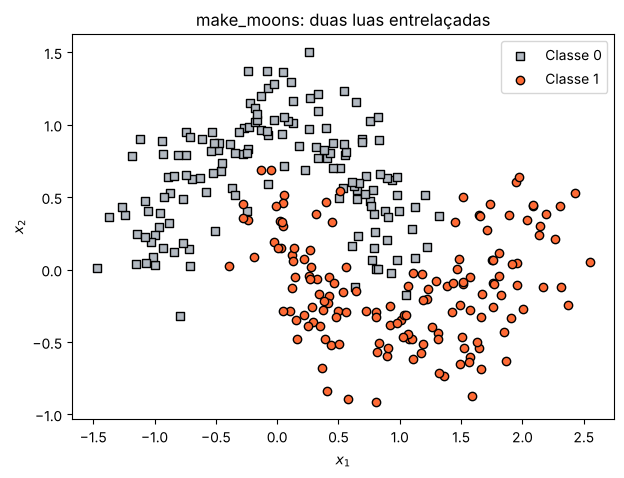

In [2]:
plt.figure(figsize=(7, 5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], c="#B2B9C1", marker="s", edgecolor="k", label="Classe 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="#FF6B35", marker="o", edgecolor="k", label="Classe 1")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.title("make_moons: duas luas entrelaçadas")
plt.legend(); plt.show()

## 03 · Separar treino e teste (75% / 25%, estratificado)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
print("Treino:", X_train.shape, "| Teste:", X_test.shape)

Treino: (225, 2) | Teste: (75, 2)


## 04 · Pipeline com StandardScaler

O SVM mede distâncias, então as duas características precisam estar na mesma escala. O `StandardScaler` fica **dentro do Pipeline**: ele aprende média e desvio só com o treino, sem vazar informação do teste.

In [4]:
def criar_svm(kernel, C=1.0, gamma="scale"):
    return Pipeline([("scaler", StandardScaler()),
                     ("svc", SVC(kernel=kernel, C=C, gamma=gamma))])

## 05 · Treinar o SVM linear

In [5]:
svm_linear = criar_svm("linear").fit(X_train, y_train)
print("Vetores de suporte:", svm_linear.named_steps["svc"].n_support_.sum())

Vetores de suporte: 69


## 06 · Treinar o SVM RBF

In [6]:
svm_rbf = criar_svm("rbf").fit(X_train, y_train)
print("Vetores de suporte:", svm_rbf.named_steps["svc"].n_support_.sum())

Vetores de suporte: 62


## 07 e 08 · Comparar os modelos e calcular a acurácia

In [7]:
resultados = {}
for nome, modelo in [("Linear", svm_linear), ("RBF", svm_rbf)]:
    tr = accuracy_score(y_train, modelo.predict(X_train))
    te = accuracy_score(y_test, modelo.predict(X_test))
    resultados[nome] = (tr, te)
    print(f"{nome:<7} | treino {tr:.3f} | teste {te:.3f}")

Linear  | treino 0.884 | teste 0.853
RBF     | treino 0.942 | teste 0.907


## 09 · Matrizes de confusão (teste)

Linear:
[[30  8]
 [ 3 34]]
RBF:
[[32  6]
 [ 1 36]]


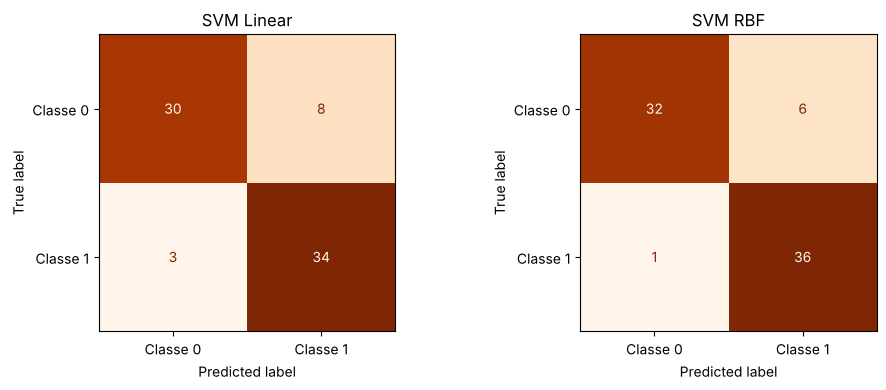

In [8]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nome, modelo) in zip(eixos, [("Linear", svm_linear), ("RBF", svm_rbf)]):
    cm = confusion_matrix(y_test, modelo.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Classe 0", "Classe 1"]).plot(ax=ax, cmap="Oranges", colorbar=False)
    ax.set_title(f"SVM {nome}")
    print(f"{nome}:\n{cm}")
plt.tight_layout(); plt.show()

## 10 · Visualizar as fronteiras

Fundo = classe prevista; linha cheia = fronteira (`decision_function = 0`); linhas tracejadas = margens (±1); círculos = vetores de suporte.

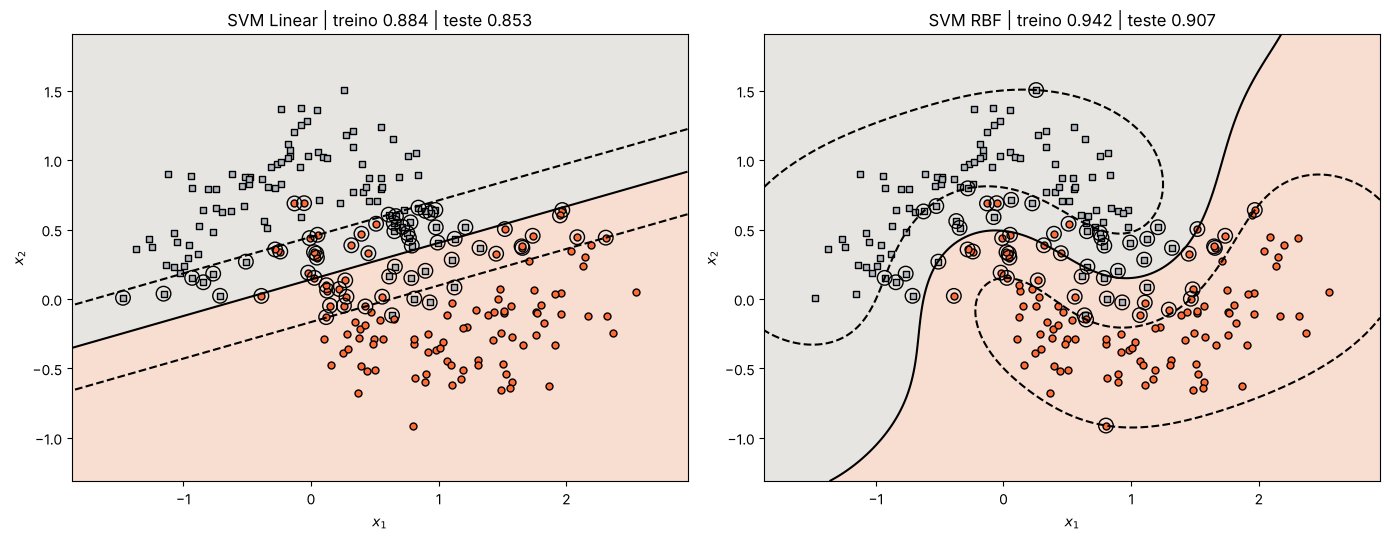

In [9]:
x_lim = (X[:, 0].min() - 0.4, X[:, 0].max() + 0.4)
y_lim = (X[:, 1].min() - 0.4, X[:, 1].max() + 0.4)

def plot_fronteira(modelo, ax, titulo, vetores=True):
    xx, yy = np.meshgrid(np.linspace(*x_lim, 300), np.linspace(*y_lim, 300))
    grade = np.c_[xx.ravel(), yy.ravel()]
    Z = modelo.predict(grade).reshape(xx.shape)
    D = modelo.decision_function(grade).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=["#E7E5E1", "#F8DED1"])
    ax.contour(xx, yy, D, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    ax.scatter(X_train[y_train == 0, 0], X_train[y_train == 0, 1], c="#B2B9C1", marker="s", edgecolor="k", s=25)
    ax.scatter(X_train[y_train == 1, 0], X_train[y_train == 1, 1], c="#FF6B35", marker="o", edgecolor="k", s=25)
    if vetores:
        sv = X_train[modelo.named_steps["svc"].support_]     # índices valem para X_train
        ax.scatter(sv[:, 0], sv[:, 1], s=110, facecolors="none", edgecolors="k", linewidths=1)
    ax.set(xlim=x_lim, ylim=y_lim, title=titulo, xlabel="$x_1$", ylabel="$x_2$")

fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, nome, modelo in [(eixos[0], "Linear", svm_linear), (eixos[1], "RBF", svm_rbf)]:
    tr, te = resultados[nome]
    plot_fronteira(modelo, ax, f"SVM {nome} | treino {tr:.3f} | teste {te:.3f}")
plt.tight_layout(); plt.show()

## 11 · Testar valores de C (RBF, gamma = "scale")

**C** é o custo de cada ponto que fica do lado errado ou dentro da margem. C pequeno aceita erros em troca de uma margem larga e uma fronteira suave; C grande tenta acertar todos os pontos do treino.

      C | treino |  teste | vet. suporte
   0.01 |  0.604 |  0.627 |          224
    0.1 |  0.898 |  0.893 |          117
      1 |  0.942 |  0.907 |           62
     10 |  0.982 |  0.973 |           39
    100 |  0.978 |  0.947 |           23
   1000 |  0.978 |  0.947 |           20


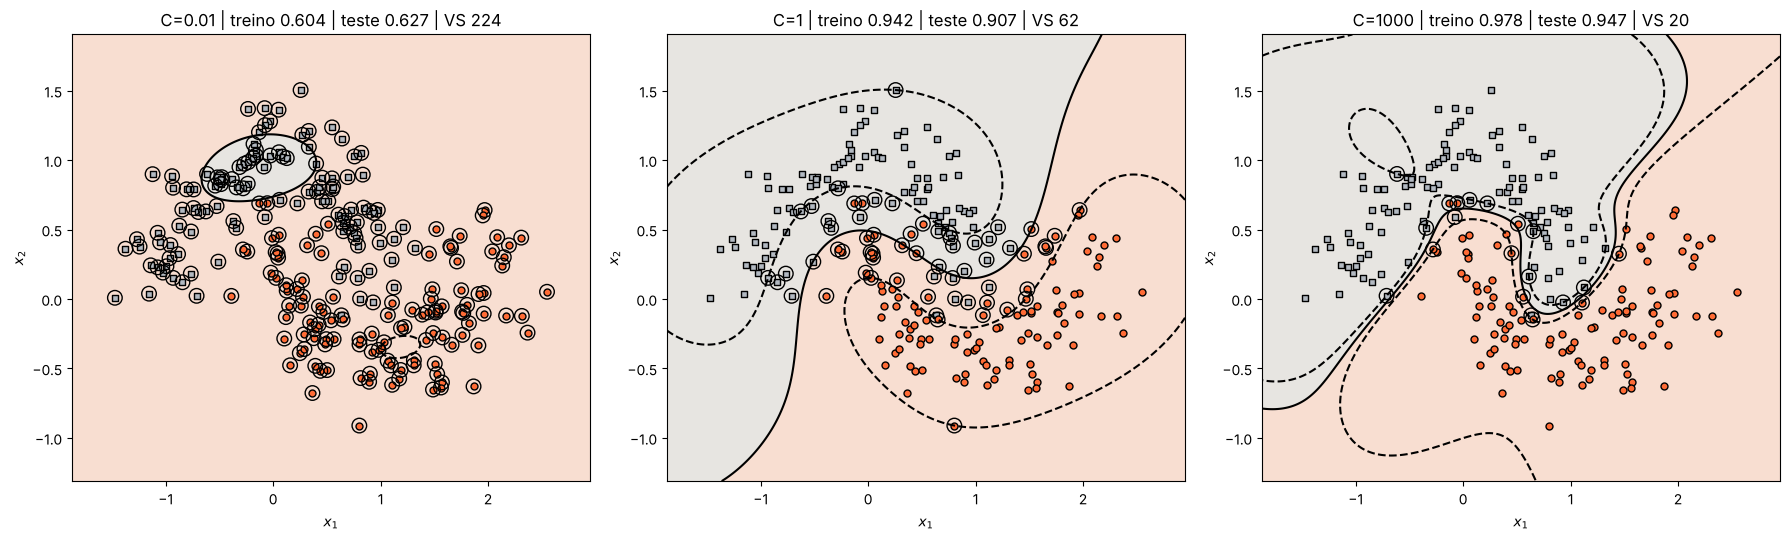

In [10]:
def avaliar(modelo):
    svc = modelo.named_steps["svc"]
    return (accuracy_score(y_train, modelo.predict(X_train)),
            accuracy_score(y_test, modelo.predict(X_test)),
            int(svc.n_support_.sum()))

valores_C = [0.01, 0.1, 1, 10, 100, 1000]
modelos_C = {c: criar_svm("rbf", C=c).fit(X_train, y_train) for c in valores_C}

print(f"{'C':>7} | {'treino':>6} | {'teste':>6} | {'vet. suporte':>12}")
for c, m in modelos_C.items():
    tr, te, vs = avaliar(m)
    print(f"{c:>7} | {tr:>6.3f} | {te:>6.3f} | {vs:>12}")

fig, eixos = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, c in zip(eixos, [0.01, 1, 1000]):
    tr, te, vs = avaliar(modelos_C[c])
    plot_fronteira(modelos_C[c], ax, f"C={c} | treino {tr:.3f} | teste {te:.3f} | VS {vs}")
plt.tight_layout(); plt.show()

## 12 · Testar valores de gamma (RBF, C = 1)

**gamma** define o alcance de cada vetor de suporte. Gamma pequeno: cada ponto influencia uma região grande, e a fronteira fica suave (quase reta). Gamma grande: a influência é bem local, e a fronteira passa a contornar pontos individuais.

  gamma | treino |  teste | vet. suporte
   0.01 |  0.867 |  0.813 |          120
    0.1 |  0.880 |  0.840 |           80
      1 |  0.969 |  0.960 |           56
     10 |  0.982 |  0.947 |          119
    100 |  1.000 |  0.893 |          216


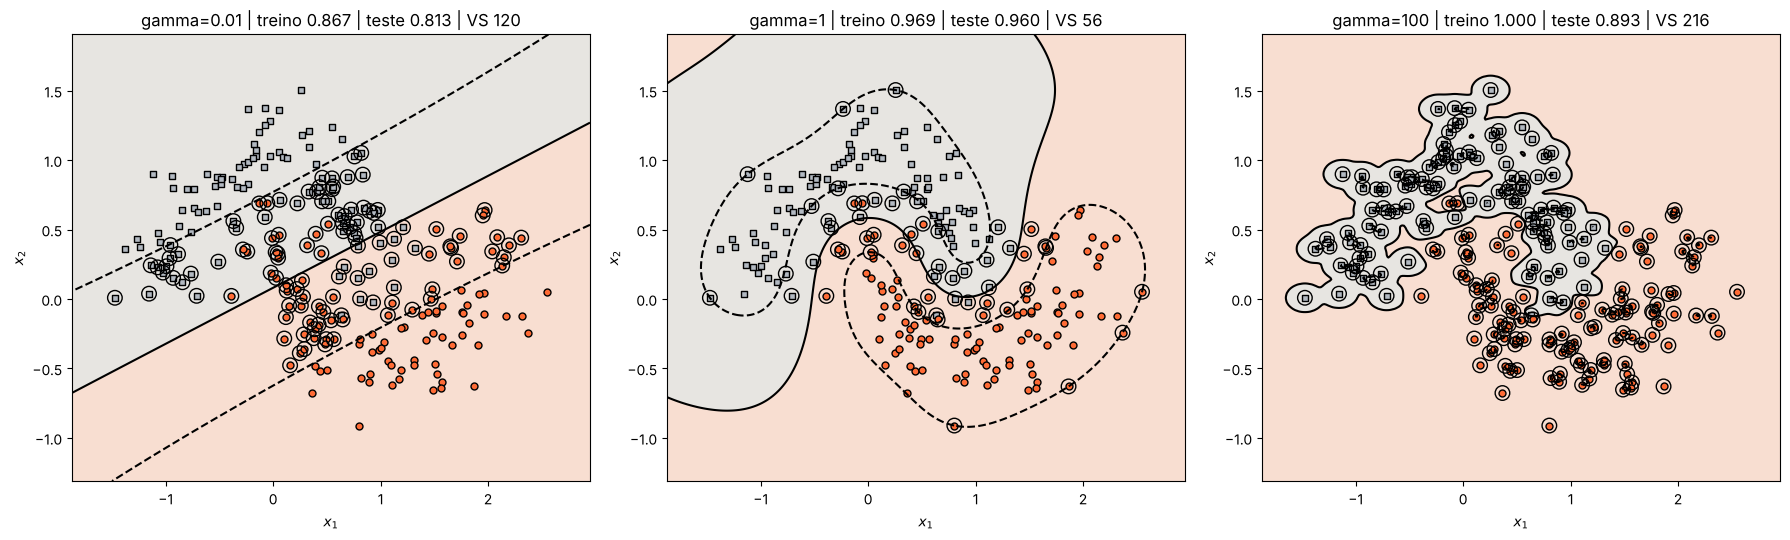

In [11]:
valores_gamma = [0.01, 0.1, 1, 10, 100]
modelos_g = {g: criar_svm("rbf", C=1, gamma=g).fit(X_train, y_train) for g in valores_gamma}

print(f"{'gamma':>7} | {'treino':>6} | {'teste':>6} | {'vet. suporte':>12}")
for g, m in modelos_g.items():
    tr, te, vs = avaliar(m)
    print(f"{g:>7} | {tr:>6.3f} | {te:>6.3f} | {vs:>12}")

fig, eixos = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, g in zip(eixos, [0.01, 1, 100]):
    tr, te, vs = avaliar(modelos_g[g])
    plot_fronteira(modelos_g[g], ax, f"gamma={g} | treino {tr:.3f} | teste {te:.3f} | VS {vs}")
plt.tight_layout(); plt.show()

### Extensão opcional · GridSearchCV

Em vez de testar C e gamma separados, a busca em grade testa **todas as combinações** com validação cruzada estratificada (5 folds) **só no treino**. O teste é usado uma única vez, no final.

Melhores hiperparâmetros: {'svc__C': 1, 'svc__gamma': 1}
Acurácia média na validação cruzada: 0.960
Acurácia no teste (uma única vez):    0.960


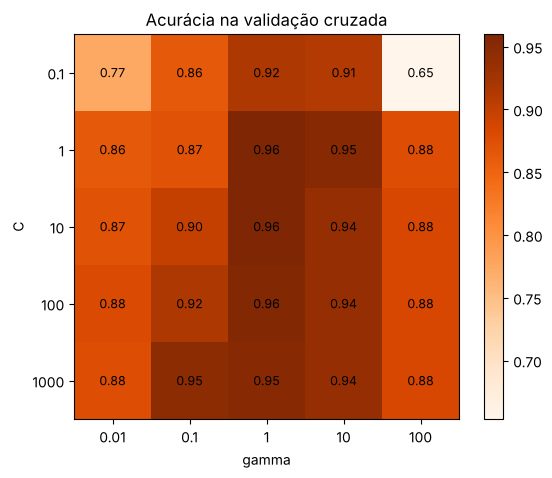

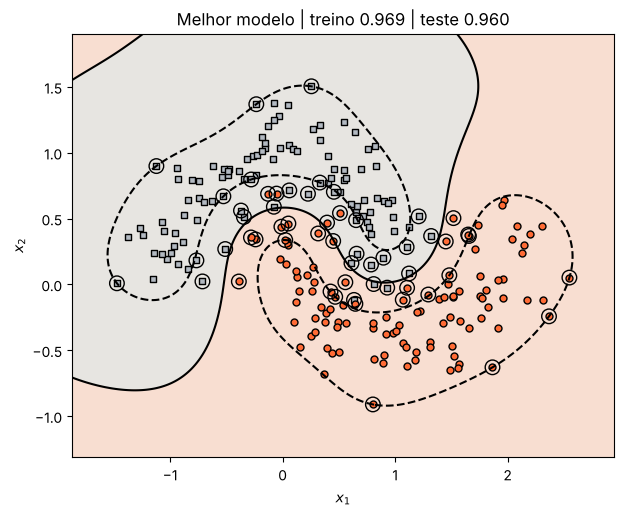

In [12]:
grade = {"svc__C": [0.1, 1, 10, 100, 1000],
         "svc__gamma": [0.01, 0.1, 1, 10, 100]}
busca = GridSearchCV(criar_svm("rbf"), grade,
                     cv=StratifiedKFold(5, shuffle=True, random_state=42),
                     scoring="accuracy").fit(X_train, y_train)

print("Melhores hiperparâmetros:", busca.best_params_)
print(f"Acurácia média na validação cruzada: {busca.best_score_:.3f}")
print(f"Acurácia no teste (uma única vez):    {busca.score(X_test, y_test):.3f}")

notas = busca.cv_results_["mean_test_score"].reshape(len(grade["svc__C"]), len(grade["svc__gamma"]))
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(notas, cmap="Oranges")
ax.set(xticks=range(5), xticklabels=grade["svc__gamma"], yticks=range(5), yticklabels=grade["svc__C"],
       xlabel="gamma", ylabel="C", title="Acurácia na validação cruzada")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{notas[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax); plt.show()

fig, ax = plt.subplots(figsize=(7, 5.5))
tr, te, vs = avaliar(busca.best_estimator_)
plot_fronteira(busca.best_estimator_, ax, f"Melhor modelo | treino {tr:.3f} | teste {te:.3f}")
plt.show()

## 13 · Interpretar os resultados

| Modelo | Treino | Teste | Vetores de suporte | Leitura |
|---|---|---|---|---|
| Linear | 0,884 | 0,853 | 69 | uma reta pega a tendência geral, mas erra nas "pontas" das luas |
| RBF (C = 1, gamma = scale) | 0,942 | 0,907 | 62 | fronteira curva, melhor que a reta |
| RBF C = 0,01 | 0,604 | 0,627 | 224 | **underfitting**: quase todos os pontos viram vetores de suporte |
| RBF C = 10 | 0,982 | 0,973 | 39 | bom equilíbrio |
| RBF gamma = 100 | **1,000** | 0,893 | 216 | **overfitting**: "ilhas" em volta de cada ponto |
| GridSearchCV (C = 1, gamma = 1) | 0,969 | **0,960** | 56 | escolhido só com validação cruzada |

**Linear × RBF.** Ao contrário do disco e anel do exercício guiado (em que o linear ficou em 49%), as luas são *parcialmente* separáveis por uma reta, por isso o linear ainda acerta 85%. O que ele não consegue é seguir a curvatura: os erros se concentram onde a ponta de uma lua entra na outra. O RBF mede a **similaridade por distância** a cada vetor de suporte, o que equivale a trabalhar num espaço de dimensão maior onde as luas ficam separáveis (o *truque do kernel*). Por isso a fronteira pode se curvar.

**C (custo dos erros).** Com C = 0,01, errar quase não custa nada: a margem fica enorme, 224 dos 225 pontos de treino viram vetores de suporte e o modelo mal aprende (60%). Aumentando C, o modelo passa a levar os erros a sério e a fronteira se ajusta às luas (C = 10: 97% no teste). A partir de C = 100, ele começa a perseguir os pontos de ruído e o teste cai um pouco (94,7%).

**Gamma (alcance de cada ponto).** Com gamma = 0,01, cada vetor de suporte influencia uma região enorme e a fronteira fica praticamente reta (81%). Com gamma = 1, ela acompanha o formato das luas (96%). Com gamma = 100, cada ponto só influencia a vizinhança imediata: a fronteira vira um conjunto de "ilhas" em volta dos pontos de treino, que acerta **100% do treino mas cai para 89% no teste**. É o caso clássico de overfitting, e o número de vetores de suporte sobe para 216, sinal de que o modelo está "decorando" pontos.

**C e gamma juntos.** Os dois controlam a complexidade da fronteira. Valores baixos levam a underfitting (fronteira simples demais); valores altos, a overfitting (fronteira presa ao ruído). O mapa de calor do GridSearchCV mostra a faixa boa no meio.

**Uma observação honesta.** O C = 10 teve um teste um pouco melhor (97,3%) que o modelo do GridSearchCV (96,0%). Mesmo assim, o certo é ficar com o GridSearchCV, porque ele escolheu os hiperparâmetros **só com o treino**. Escolher olhando o teste seria vazamento: o 97,3% seria otimista e não valeria para dados novos.

**O escalonamento** ficou dentro do `Pipeline` em todos os modelos, inclusive na busca em grade: em cada fold, o `StandardScaler` aprende só com a parte de treino daquele fold.

## Conclusão

O SVM RBF é melhor que o linear quando a fronteira real é curva, mas ele só funciona bem com **C e gamma ajustados**. A melhor configuração (C = 1, gamma = 1, escolhida por validação cruzada) acertou **96% do teste**, contra 85% do linear. A lição principal: acurácia de treino alta não basta. O gamma = 100 acertou tudo no treino e foi pior no teste, e é o desempenho em dados que o modelo nunca viu que importa.